In [ ]:
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import neurokit2 as nk
import numpy as np
import pandas as pd
import seaborn as sns

from stress_tfm.features.ecg import get_ecg_features
from stress_tfm.features.eda import get_eda_features
from stress_tfm.features.respiration import get_resp_features

warnings.filterwarnings("ignore")


def _fill_nan(arr: np.ndarray) -> np.ndarray:
    """Forward-fill NaNs in a 1D numpy array via linear interpolation."""
    if not np.isnan(arr).any():
        return arr
    mask = ~np.isnan(arr)
    if mask.sum() == 0:
        return np.zeros_like(arr)
    idx = np.arange(len(arr))
    return np.interp(idx, idx[mask], arr[mask])


# ─── Config ───────────────────────────────────────────────────
SR = 500
DATA_DIR = Path("../data/raw/Physiological")
LABELS_FILE = Path("../data/raw/labels.csv")
OUTPUT = Path("../data/master_table.parquet")


now = datetime.now()

print(f"Last notebook execution: {now}")

Last notebook execution: 2026-11-19 21:27:11.123942


In [2]:
labels_df = pd.read_csv(LABELS_FILE, sep=",")
labels_df.columns = ["file_id", "label_binary", "label_3class"]

print(f"Labels: {len(labels_df)} rows")
print(labels_df.head(10))
print(f"\nBinary: {labels_df['label_binary'].value_counts().to_dict()}")
print(f"3-class: {labels_df['label_3class'].value_counts().to_dict()}")

Labels: 700 rows
          file_id  label_binary  label_3class
0  2ea4_Breathing             0             0
1  2ea4_Counting1             1             2
2  2ea4_Counting2             1             2
3  2ea4_Counting3             1             2
4       2ea4_Math             1             2
5    2ea4_Reading             0             0
6      2ea4_Relax             0             0
7   2ea4_Speaking             1             2
8     2ea4_Stroop             0             0
9     2ea4_Video1             0             1

Binary: {1: 368, 0: 332}
3-class: {0: 253, 2: 245, 1: 202}


In [3]:
# ─── Pre-check: identify flatline signals (std == 0) ─────────
filelist = sorted(
    [
        f
        for d in DATA_DIR.iterdir()
        if d.is_dir()
        for f in d.iterdir()
        if f.suffix == ".txt" and not f.name.startswith(".")
    ]
)

flatline_files = []

for f in filelist:
    df = pd.read_csv(f, sep=",")
    signals = {"ECG": df.iloc[:, 0], "EDA": df.iloc[:, 1], "RR": df.iloc[:, 2]}
    for name, col in signals.items():
        if col.std() == 0:
            flatline_files.append((f.stem, name, col.mean()))

if flatline_files:
    print(
        f"⚠ {len(flatline_files)} flatline signal(s) detected (z-score will produce NaN):"
    )
    for file_id, sig, val in flatline_files:
        print(f"  {file_id} → {sig} (constant = {val:.4f})")
else:
    print("✓ No flatline signals detected.")

⚠ 1 flatline signal(s) detected (z-score will produce NaN):
  r5s8_Counting3 → EDA (constant = 65535.0000)


In [4]:
data_ecg = {}
data_eda = {}
data_rsp = {}

filelist = sorted(
    [
        f
        for d in DATA_DIR.iterdir()
        if d.is_dir()
        for f in d.iterdir()
        if f.suffix == ".txt" and not f.name.startswith(".")
    ]
)

print(f"Found {len(filelist)} files")

for f in filelist:
    file_id = f.stem
    df = pd.read_csv(f, sep=",")

    ecg = (df.iloc[:, 0] - df.iloc[:, 0].mean()) / df.iloc[:, 0].std()
    eda = (df.iloc[:, 1] - df.iloc[:, 1].mean()) / df.iloc[:, 1].std()
    rsp = (df.iloc[:, 2] - df.iloc[:, 2].mean()) / df.iloc[:, 2].std()

    data_ecg[file_id] = nk.ecg_clean(
        _fill_nan(ecg.values), sampling_rate=SR, method="biosppy"
    )
    data_eda[file_id] = nk.eda_clean(
        _fill_nan(eda.values), sampling_rate=SR, method="biosppy"
    )
    data_rsp[file_id] = nk.rsp_clean(
        _fill_nan(rsp.values), sampling_rate=SR, method="biosppy"
    )

data_ecg.pop("r5s8_Counting3", None)
data_eda.pop("r5s8_Counting3", None)
data_rsp.pop("r5s8_Counting3", None)

# "One recording (r5s8_Counting3) contained a
# flatline EDA signal (constant value 65535,
# indicating sensor failure) and was excluded
# from the analysis, consistent with the
# official StressID baseline."

print(f"Loaded {len(data_ecg)} signals (after exclusion)")

Found 774 files
Loaded 773 signals (after exclusion)


In [5]:
df_ecg = get_ecg_features(data_ecg, sampling_freq=SR)
print(f"ECG: {df_ecg.shape[0]} rows × {df_ecg.shape[1]} features")

df_eda = get_eda_features(data_eda, sampling_freq=SR)
print(f"EDA: {df_eda.shape[0]} rows × {df_eda.shape[1]} features")

df_rsp = get_resp_features(data_rsp, sampling_freq=SR)
print(f"RSP: {df_rsp.shape[0]} rows × {df_rsp.shape[1]} features")

ECG: 773 rows × 46 features
EDA: 773 rows × 24 features
RSP: 773 rows × 62 features


In [6]:
# Merge all modality features (indexed by file_id)
df_features = pd.concat([df_ecg, df_rsp, df_eda], axis=1)
print(f"Merged: {df_features.shape}")

# Derive subject_id and task_id from filename
df_features["subject_id"] = df_features.index.str.split("_").str[0]
df_features["task_id"] = df_features.index.str.split("_", n=1).str[1]

# Join labels
df_features = df_features.join(labels_df.set_index("file_id"), how="inner")

# Safety: drop rows without a label
n_before = len(df_features)
df_features = df_features.dropna(subset=["label_binary", "label_3class"])
print(
    f"Rows after label join: {len(df_features)} (dropped {n_before - len(df_features)})"
)

Merged: (773, 132)
Rows after label join: 699 (dropped 0)


In [7]:
id_cols = ["subject_id", "task_id", "label_binary", "label_3class"]
feature_cols = [c for c in df_features.columns if c not in id_cols]

df_features.index.name = "file_id"
df_features = df_features[id_cols + feature_cols].reset_index()
df_features.index.name = None

print(f"Final table: {df_features.shape[0]} rows × {df_features.shape[1]} cols")
print(f"  → {df_features['subject_id'].nunique()} subjects")
print(f"  → {len(feature_cols)} features")
print(f"  → Binary: {df_features['label_binary'].value_counts().to_dict()}")
print(f"  → 3-class: {df_features['label_3class'].value_counts().to_dict()}")

OUTPUT.parent.mkdir(parents=True, exist_ok=True)
df_features.to_parquet(OUTPUT, index=False)
print(f"\nSaved → {OUTPUT}")

Final table: 699 rows × 137 cols
  → 64 subjects
  → 132 features
  → Binary: {1: 367, 0: 332}
  → 3-class: {0: 253, 2: 244, 1: 202}

Saved → ../data/master_table.parquet


In [8]:
id_cols = ["subject_id", "task_id", "label_binary", "label_3class"]
feature_cols = [c for c in df_features.columns if c not in id_cols]

# 1. NaNs in feature columns
nan_counts = df_features[feature_cols].isna().sum()
n_nan_cols = (nan_counts > 0).sum()
print(f"Columns with NaNs: {n_nan_cols}/{len(feature_cols)}")
if n_nan_cols > 0:
    print(nan_counts[nan_counts > 0].to_string())

# 2. Per-subject row counts
rows_per_subject = df_features.groupby("subject_id").size()
print(
    f"\nRows per subject: min={rows_per_subject.min()}, max={rows_per_subject.max()}, mean={rows_per_subject.mean():.1f}"
)

# 3. Per-task label consistency
task_labels = df_features.groupby("task_id")[["label_binary", "label_3class"]].nunique()
inconsistent = task_labels[task_labels.max(axis=1) > 1]
print(f"\nTasks with inconsistent labels: {len(inconsistent)}")
if len(inconsistent) > 0:
    print(inconsistent)

# 4. Spot-check feature ranges
print("\nSpot-check ranges:")
print(
    f"  RMSSD:       [{df_features['RMSSD'].min():.1f}, {df_features['RMSSD'].max():.1f}]"
)
print(
    f"  LF/HF:       [{df_features['LF/HF'].min():.2f}, {df_features['LF/HF'].max():.2f}]"
)
print(
    f"  nSCR:        [{df_features['nSCR'].min():.1f}, {df_features['nSCR'].max():.1f}]"
)
print(
    f"  meanRR (rsp):[{df_features['meanRR'].min():.1f}, {df_features['meanRR'].max():.1f}]"
)
print(
    f"  SD1 (ECG):   [{df_features['SD1'].min():.1f}, {df_features['SD1'].max():.1f}]"
)

Columns with NaNs: 0/133

Rows per subject: min=10, max=11, mean=10.9

Tasks with inconsistent labels: 11
           label_binary  label_3class
task_id                              
Breathing             2             3
Counting1             2             3
Counting2             2             3
Counting3             2             3
Math                  2             3
Reading               2             3
Relax                 2             3
Speaking              2             3
Stroop                2             3
Video1                2             3
Video2                2             3

Spot-check ranges:
  RMSSD:       [4.7, 3691.6]
  LF/HF:       [0.01, 48.41]
  nSCR:        [0.3, 31.0]
  meanRR (rsp):[6.4, 17.8]
  SD1 (ECG):   [1.7, 1305.2]


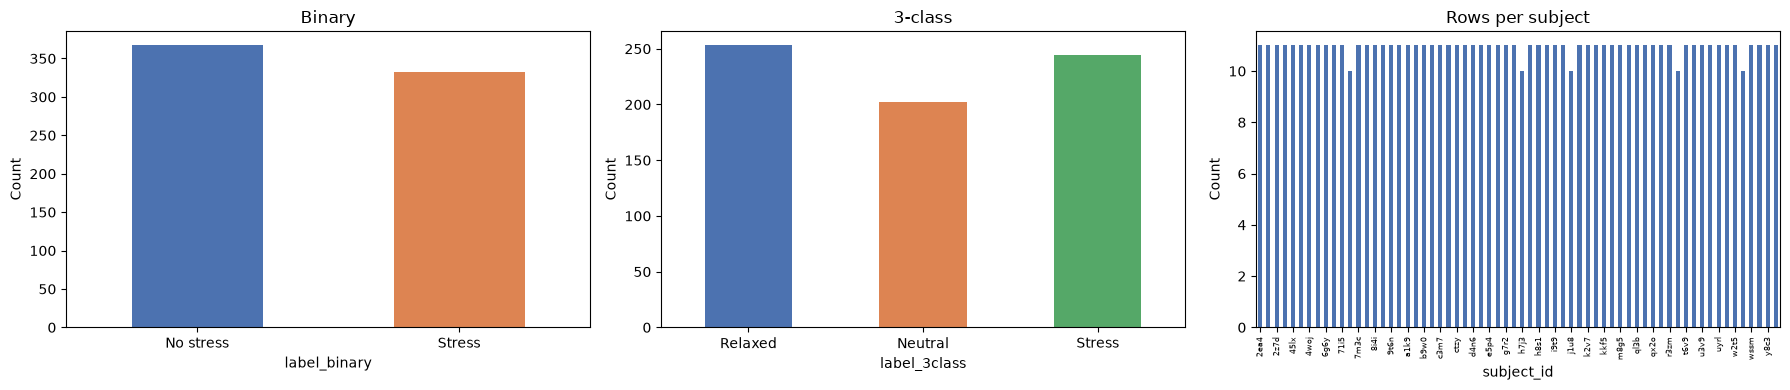

In [ ]:
sns.set_palette("deep")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Binary balance
df_features["label_binary"].value_counts().plot(
    kind="bar", ax=axes[0], color=sns.color_palette("deep")[:2]
)
axes[0].set_title("Binary")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(["No stress", "Stress"], rotation=0)

# 3-class balance
df_features["label_3class"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color=sns.color_palette("deep")[:3]
)
axes[1].set_title("3-class")
axes[1].set_ylabel("Count")
axes[1].set_xticklabels(["Relaxed", "Neutral", "Stress"], rotation=0)

# Rows per subject
rows_per_subject.plot(kind="bar", ax=axes[2], color=sns.color_palette("deep")[0])
axes[2].set_title("Rows per subject")
axes[2].set_ylabel("Count")
axes[2].tick_params(axis="x", rotation=90, labelsize=6)
axes[2].set_xticks(range(0, len(rows_per_subject), 2))

plt.tight_layout()
# plt.savefig("figures/eda_overview.pdf", bbox_inches="tight")
plt.show()